# Trabalho 02 — Redes Neurais: Fashion-MNIST

**UFSC · Sistemas Inteligentes (INE5633)**  
**Professora:** Nathalia da Cruz Alves  
**Entrega:** 15/11/2026 · grupo de 2 a 3 estudantes

## Equipe e contribuições

| Estudante | Contribuição efetiva |
| --- | --- |
| Preencher | Descrever em uma frase |
| Preencher | Descrever em uma frase |

Adicionar uma terceira linha se necessário.

**Estado deste notebook:** dados, MLP, CNN e busca de hiperparâmetros executados,
com saídas salvas. A avaliação final no teste ainda está a desenvolver.
As seções abaixo seguem o [enunciado](<doc/Trabalho Prático 2 - Redes Neurais.pdf>).

## Plano de desenvolvimento

1. Preparar o ambiente, carregar e conhecer os dados.
2. Treinar uma **MLP sem convoluções** e analisar loss/acurácia de treino e validação.
3. Treinar uma **CNN com aumento de dados**, analisar as curvas e comparar com a MLP.
4. Testar hiperparâmetros da CNN e organizar uma tabela dos experimentos.
5. Avaliar a melhor CNN no teste, com loss, acurácia e matriz de confusão.
6. Elaborar conclusões, registrar referências e preparar o vídeo de até 8 minutos.

Antes de cada implementação, explicar a escolha e o conceito envolvido.
Preencher as análises com os resultados medidos e manter as saídas das células salvas.

## 1. Ambiente e reprodutibilidade

Usaremos TensorFlow/Keras, como nas aulas práticas. A seed 42 controla a divisão
estratificada e as fontes usuais de aleatoriedade. As versões e os dispositivos são
registrados para permitir comparar execuções; desempenho e reprodução podem variar
entre ambientes. O notebook pode rodar em CPU, embora os treinamentos sejam mais lentos.

Abra este arquivo pelo Jupyter da disciplina ou instale `requirements.txt` em um
ambiente virtual. O Keras Tuner será necessário somente na etapa de otimização.

In [1]:
import gzip
import importlib.metadata
import json
from pathlib import Path
import platform
import struct
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)

# O kernel deve partir desta pasta ou de um de seus subdiretórios.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'scripts' / 'baixar_dados.py').is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError('Abra o notebook na pasta Trabalho 02 do repositório.')

DADOS = RAIZ / 'dados' / 'fashion-mnist'
RESULTADOS = RAIZ / 'resultados'
MODELOS = RAIZ / 'modelos'
for pasta in (RESULTADOS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

versoes = {'python': platform.python_version()}
for pacote in ('tensorflow', 'numpy', 'pandas', 'matplotlib', 'scikit-learn'):
    versoes[pacote] = importlib.metadata.version(pacote)
print(json.dumps(versoes, indent=2))
print('GPUs disponíveis:', tf.config.list_physical_devices('GPU'))
print('Seed:', SEED)
(RESULTADOS / 'ambiente.json').write_text(
    json.dumps({'seed': SEED, 'versoes': versoes}, indent=2), encoding='utf-8'
)

I0000 00:00:1794090692.871681   89079 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794090692.922882   89079 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794090693.971766   89079 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


{
  "python": "3.13.14",
  "tensorflow": "2.21.0",
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "matplotlib": "3.11.1",
  "scikit-learn": "1.9.0"
}
GPUs disponíveis: []
Seed: 42


E0000 00:00:1794090694.651331   89079 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


190

## 2. Download e carregamento do Fashion-MNIST

O [dataset oficial da Zalando](https://github.com/zalandoresearch/fashion-mnist)
contém imagens de roupas 28 × 28 em escala de cinza e dez rótulos. Existem
60.000 exemplos no treino oficial e 10.000 no teste. Os quatro arquivos compactados
são guardados em `dados/fashion-mnist/`, fora do versionamento.

O script verifica os checksums MD5 publicados antes de reaproveitar arquivos.
Com os dados íntegros no disco, esta etapa funciona sem rede. O leitor abaixo usa
o formato IDX original, conferindo cabeçalhos e tamanhos; não utiliza o MNIST de dígitos.

In [2]:
subprocess.run([sys.executable, str(RAIZ / 'scripts' / 'baixar_dados.py')], check=True)


def carregar_idx(prefixo):
    with gzip.open(DADOS / f'{prefixo}-images-idx3-ubyte.gz', 'rb') as arquivo:
        magic, quantidade, altura, largura = struct.unpack('>IIII', arquivo.read(16))
        assert magic == 2051 and (altura, largura) == (28, 28)
        imagens = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert imagens.size == quantidade * altura * largura
        imagens = imagens.reshape(quantidade, altura, largura)
    with gzip.open(DADOS / f'{prefixo}-labels-idx1-ubyte.gz', 'rb') as arquivo:
        magic, total_rotulos = struct.unpack('>II', arquivo.read(8))
        assert magic == 2049 and total_rotulos == quantidade
        rotulos = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert rotulos.size == quantidade and np.all(rotulos < 10)
    return imagens, rotulos


# Carregar o teste somente na seção 6, após selecionar o modelo.
X_oficial, y_oficial = carregar_idx('train')
assert X_oficial.shape == (60000, 28, 28)
print('Treino oficial:', X_oficial.shape, y_oficial.shape)
print('Pixels:', X_oficial.dtype, '| intervalo:', X_oficial.min(), X_oficial.max())

OK (já disponível): train-images-idx3-ubyte.gz
OK (já disponível): train-labels-idx1-ubyte.gz
OK (já disponível): t10k-images-idx3-ubyte.gz
OK (já disponível): t10k-labels-idx1-ubyte.gz
Dados disponíveis em: /home/jovyan/work/dados/fashion-mnist


Treino oficial: (60000, 28, 28) (60000,)
Pixels: uint8 | intervalo: 0 255


## 3. Separação de treino/validação e exploração

Reservamos 20% do treino oficial para validação, preservando a proporção das
classes por estratificação. Todos os modelos devem usar os mesmos índices: isso
permite comparar MLP, CNN e configurações sem alterar a dificuldade da validação.
Os índices são salvos em `resultados/divisao_dados.npz`.

Exploramos somente dados de treino. Os rótulos abaixo são traduções dos nomes
publicados pela Zalando; a numeração original é preservada.

,classe,treino,validacao
0,Camiseta/top,4800,1200
1,Calça,4800,1200
2,Suéter,4800,1200
3,Vestido,4800,1200
4,Casaco,4800,1200
5,Sandália,4800,1200
6,Camisa,4800,1200
7,Tênis,4800,1200
8,Bolsa,4800,1200
9,Bota de cano curto,4800,1200


Treino: 48000 | Validação: 12000


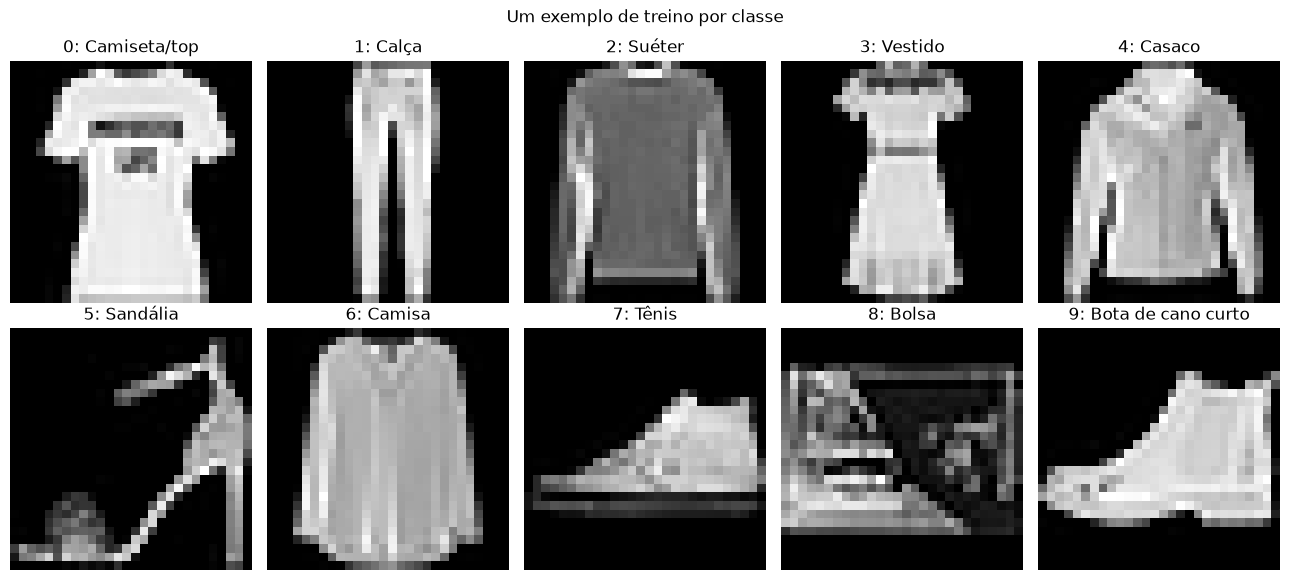

In [3]:
NOMES_CLASSES = [
    'Camiseta/top', 'Calça', 'Suéter', 'Vestido', 'Casaco',
    'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota de cano curto',
]
indices_treino, indices_validacao = train_test_split(
    np.arange(len(y_oficial)), test_size=0.2, random_state=SEED,
    stratify=y_oficial,
)
assert not np.intersect1d(indices_treino, indices_validacao).size
assert len(indices_treino) + len(indices_validacao) == len(y_oficial)
np.savez(RESULTADOS / 'divisao_dados.npz',
         treino=indices_treino, validacao=indices_validacao, seed=SEED)

contagens = pd.DataFrame({
    'classe': NOMES_CLASSES,
    'treino': np.bincount(y_oficial[indices_treino], minlength=10),
    'validacao': np.bincount(y_oficial[indices_validacao], minlength=10),
})
display(contagens)
print(f'Treino: {len(indices_treino)} | Validação: {len(indices_validacao)}')

fig, eixos = plt.subplots(2, 5, figsize=(13, 6))
for classe, eixo in enumerate(eixos.flat):
    candidatos = indices_treino[y_oficial[indices_treino] == classe]
    eixo.imshow(X_oficial[candidatos[0]], cmap='gray', vmin=0, vmax=255)
    eixo.set_title(f'{classe}: {NOMES_CLASSES[classe]}')
    eixo.axis('off')
fig.suptitle('Um exemplo de treino por classe')
fig.tight_layout()
fig.savefig(RESULTADOS / 'exemplos_treino.png', dpi=150, bbox_inches='tight')
plt.show()

### Normalização e formato das entradas

Convertemos os pixels para `float32` e dividimos por 255 para usar a escala [0, 1].
A transformação é fixa e não estima estatísticas da validação. Mantemos um canal
explícito para a CNN: `(amostras, 28, 28, 1)`. A MLP poderá receber o mesmo tensor
e usar uma camada `Flatten` para convertê-lo em um vetor de 784 valores.

Aumento de dados será aplicado apenas durante o treinamento da CNN. Validação
e teste devem preservar as imagens originais normalizadas.

In [4]:
X_train = X_oficial[indices_treino].astype('float32')[..., np.newaxis] / 255.0
X_val = X_oficial[indices_validacao].astype('float32')[..., np.newaxis] / 255.0
y_train = y_oficial[indices_treino]
y_val = y_oficial[indices_validacao]

assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert 0 <= X_train.min() <= X_train.max() <= 1
print('Treino:', X_train.shape, y_train.shape, X_train.dtype)
print('Validação:', X_val.shape, y_val.shape, X_val.dtype)
print('Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.')

Treino: (48000, 28, 28, 1) (48000,) float32
Validação: (12000, 28, 28, 1) (12000,) float32
Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.


## 4. MLP: implementação, treinamento e análise (item 1)

### Passo 1 — Construir e compilar a rede

**Base prática:** seção “Multilayer Perceptron (MLP)”, função `treinar_mlp`,
da [Aula 19 — Perceptron](Aulas_Praticas/Aula_19_Perceptron_Estudante.ipynb),
de autoria da Profa. Nathalia da Cruz Alves. Esse é o arquivo disponível nesta pasta;
as orientações do projeto o mencionam como Aula 20. Preservamos o material original.

Seguimos a construção com `tf.keras.Sequential`, camadas `Dense`, ativação `tanh`,
compilação com Adam e treinamento com `fit`. A camada oculta combina os pixels com
pesos e vieses; a ativação não linear permite aprender relações mais complexas.
Adaptamos o exemplo XOR da aula às dez classes de roupas:

- **Entrada:** cada imagem tem formato `(28, 28, 1)`. `Flatten` reorganiza seus
  784 pixels em um vetor, sem aprender pesos e sem realizar convoluções.
- **Camada oculta:** 128 neurônios com `tanh`, mantendo a ativação usada na MLP
  da aula. A quantidade de neurônios é uma configuração inicial para as imagens,
  não um valor obtido por otimização.
- **Saída:** dez neurônios com `softmax`, que produz probabilidades cuja soma é 1.
  A classe prevista é a de maior probabilidade. A saída binária do XOR não serve
  para distinguir as dez classes do Fashion-MNIST.
- **Otimizador:** Adam, como na MLP da aula, com taxa de aprendizagem 0,001.
  Usamos uma taxa menor que a do exemplo XOR para este problema de imagens.
- **Perda:** `sparse_categorical_crossentropy`, apropriada às dez classes com
  rótulos inteiros de 0 a 9; não é necessário converter os rótulos para one-hot.

**Como calcular as métricas?** Para $N$ imagens, a acurácia é a fração de previsões
corretas: $\mathrm{acurácia} = \frac{1}{N}\sum_i \mathbf{1}(\hat{y}_i = y_i)$.
A perda utilizada é a média do negativo do logaritmo natural da probabilidade
atribuída à classe verdadeira: $\mathrm{loss} = -\frac{1}{N}\sum_i \log p(y_i\mid x_i)$.
O treinamento ajusta os pesos para reduzir essa perda.

As métricas **não são proporcionais**: a acurácia considera apenas a classe de
maior probabilidade, enquanto a perda considera a probabilidade da classe correta.
Por exemplo, se a classe correta já for a mais provável, aumentar sua probabilidade
de 0,4 para 0,8 mantém o acerto, mas reduz a perda de aproximadamente 0,916 para
0,223. Uma previsão errada com muita confiança pode aumentar bastante a perda.

In [5]:
# Adaptado da Aula Prática 19, treinar_mlp.
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_mlp = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax'),
])

model_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Passo 2 — Treinar e registrar os resultados

Uma época corresponde a uma passagem pelas 48.000 imagens de treino. Usaremos
**20 épocas e lotes de 32 imagens**, com parada ao completar as 20 épocas, sem
parada antecipada. São escolhas iniciais documentadas, sem busca de hiperparâmetros.
A seed é 42, com as limitações de reprodução já descritas na seção 1.

Como na aula, `fit` devolve um histórico com as métricas por época. Acrescentamos
`validation_data=(X_val, y_val)` para avaliar as mesmas 12.000 imagens de validação
ao final de cada época. A validação não atualiza os pesos; o teste continua reservado.
A MLP recebe as imagens já normalizadas, sem aumento de dados.

Salvamos o histórico em CSV e o modelo da última época em `modelos/mlp.keras`.
A tabela mostra a primeira e a última época. As métricas de treino são acumuladas
durante as atualizações dos pesos; as de validação são calculadas ao final de cada
época, com os pesos fixos. Por isso, elas não medem exatamente a mesma situação.

In [6]:
history_mlp = model_mlp.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=2,
)

historico_mlp = pd.DataFrame(history_mlp.history)
historico_mlp.index = pd.RangeIndex(1, len(historico_mlp) + 1, name='epoca')
historico_mlp.to_csv(RESULTADOS / 'historico_mlp.csv')
model_mlp.save(MODELOS / 'mlp.keras')

display(historico_mlp.iloc[[0, -1]])
print('Época de menor loss de validação:', historico_mlp['val_loss'].idxmin())

Epoch 1/20


W0000 00:00:1794089501.036909   83807 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


1500/1500 - 4s - 3ms/step - accuracy: 0.8197 - loss: 0.4992 - val_accuracy: 0.8455 - val_loss: 0.4168


Epoch 2/20


1500/1500 - 3s - 2ms/step - accuracy: 0.8612 - loss: 0.3816 - val_accuracy: 0.8608 - val_loss: 0.3745


Epoch 3/20


... (33 outputs left out)

Epoch 20/20


1500/1500 - 3s - 2ms/step - accuracy: 0.9383 - loss: 0.1704 - val_accuracy: 0.8860 - val_loss: 0.3603


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.819708,0.499190,0.8455,0.416802
20,0.938333,0.170362,0.8860,0.360267


Época de menor loss de validação: 6


### Passo 3 — Comparar as curvas de treino e validação

Adaptamos a função `plot_metrics` da aula: mantemos os dois gráficos lado a lado
e acrescentamos as curvas de validação e as legendas. O eixo horizontal começa
na época 1. No gráfico de perda, valores menores são melhores; no de acurácia,
valores maiores são melhores.

Se a perda de treino continuar caindo enquanto a de validação cresce, isso sugere
sobreajuste. Resultados fracos nos dois conjuntos podem sugerir subajuste. Essas
conclusões precisam ser verificadas nas curvas e nos valores reais abaixo.

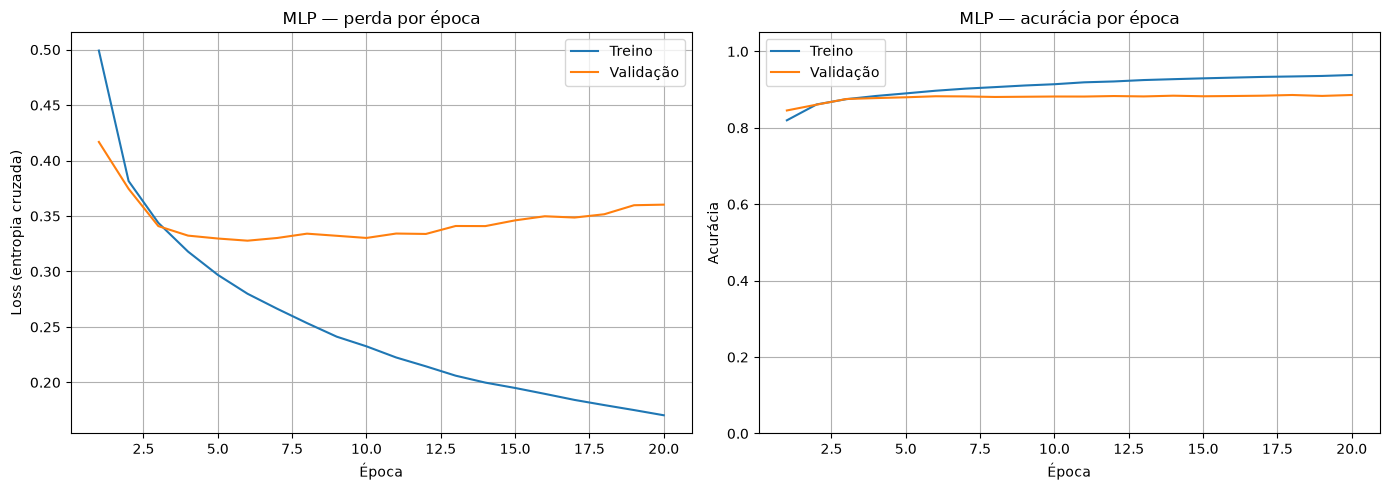

In [7]:
# Adaptado de plot_metrics da aula, incluindo as curvas de validação.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(historico_mlp.index, historico_mlp['loss'], label='Treino')
ax[0].plot(historico_mlp.index, historico_mlp['val_loss'], label='Validação')
ax[0].set_title('MLP — perda por época')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Loss (entropia cruzada)')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(historico_mlp.index, historico_mlp['accuracy'], label='Treino')
ax[1].plot(historico_mlp.index, historico_mlp['val_accuracy'], label='Validação')
ax[1].set_title('MLP — acurácia por época')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Acurácia')
ax[1].set_ylim(0, 1.05)
ax[1].grid(True)
ax[1].legend()

fig.tight_layout()
fig.savefig(RESULTADOS / 'curvas_mlp.png', dpi=150, bbox_inches='tight')
plt.show()

### Passo 4 — Analisar os resultados da MLP

O treinamento foi executado por **20 épocas**, utilizando 48.000 imagens de treino
e 12.000 de validação, com as saídas e os gráficos salvos neste notebook.
Os valores abaixo foram obtidos do histórico real desta execução:

| Momento | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | --- | --- | --- | --- |
| Época 1 | 0,4992 | 81,97% | 0,4168 | 84,55% |
| Época 6 (menor loss de validação) | 0,2799 | 89,71% | 0,3278 | 88,27% |
| Época 20 | 0,1704 | 93,83% | 0,3603 | 88,60% |

**O desempenho é satisfatório?** Como resultado inicial para comparação com a CNN,
sim: a MLP classificou corretamente cerca de 88,60% das imagens de validação.
Esse resultado é bem superior aos 10% de acerto de um classificador que sempre
escolhesse uma única classe, pois a validação tem a mesma quantidade de imagens
de cada classe. Entretanto, não há um limite de acurácia exigido no enunciado,
e esse resultado não demonstra que a configuração seja a melhor possível.

**Há sobreajuste ou subajuste?** Há indícios de sobreajuste após a época 6:
a loss de treino continua diminuindo até 0,1704, enquanto a loss de validação,
que atingiu 0,3278 na época 6, termina em 0,3603. A acurácia de treino continua
crescendo, mas a de validação fica próxima de 88%. Na última época, a diferença
entre as acurácias é de aproximadamente 5,23 pontos percentuais. O comportamento
predominante não sugere subajuste: a rede melhora no treino sem obter uma melhora
equivalente na validação.

**Como as curvas mostram que as métricas não são proporcionais?** Entre as épocas
6 e 20, a acurácia de validação sobe ligeiramente, de 88,27% para 88,60%, mas a
loss de validação também sobe, de 0,3278 para 0,3603. Isso é possível porque
acertar mais classes não garante uma probabilidade maior para a classe verdadeira
em todas as imagens. O comportamento é compatível, por exemplo, com erros mais
confiantes, mas as métricas agregadas não permitem afirmar que essa seja a única causa.

**O que podemos dizer sobre generalização?** A validação mostra que a rede aprendeu
padrões úteis para imagens que não participaram das atualizações dos pesos.
Ainda assim, a diferença para o treino e a subida da loss de validação limitam
essa conclusão. A análise se baseia em uma única divisão e execução; fixar a seed
não garante reprodução exata em todos os ambientes.

O arquivo `modelos/mlp.keras` contém os pesos da **última época**, e não os da
época de menor loss de validação. A época 6 foi identificada pelo histórico para
análise; não restauramos seus pesos. O conjunto de teste não foi usado nesta etapa
e permanece reservado para a avaliação final da melhor CNN após a otimização.

## 5. CNN com aumento de dados (item 2)

### Passo 1 — Definir e visualizar o aumento de dados

**Base prática:** seção “CNN com aumento de dados”, `data_augmentation`, `model3`
e gráficos de `history3` da [Aula 21 — CNN](Aulas_Praticas/Aula_21_CNN_MNIST_ESTUDANTE.ipynb),
de autoria da Profa. Nathalia da Cruz Alves. Mantemos as camadas e a sequência
da CNN dessa seção, utilizando o Fashion-MNIST já preparado.
A [documentação do item 2](doc/ITEM_2_CNN.md) detalha os elementos da implementação.

O aumento de dados gera versões transformadas das imagens de treino. O objetivo
é expor o modelo a pequenas variações de posição, orientação e escala, reduzindo
sua dependência da apresentação exata de cada imagem. Isso pode contribuir para
a generalização, mas não garante melhoria: o resultado precisa ser medido.

Usamos as mesmas três técnicas da aula, com os seguintes fatores:

- `RandomRotation(0.05)`: rotações de até aproximadamente **±18 graus**. O fator
  representa uma fração de uma volta completa, não uma quantidade em graus.
  Reduzimos o fator 0,1 da aula para preservar melhor a orientação das roupas.
- `RandomTranslation(0.1, 0.1)`: deslocamentos verticais e horizontais de até 10%
  da dimensão, aproximadamente 2,8 pixels em imagens de 28 × 28.
- `RandomZoom(0.1)`: pequenos aumentos ou reduções de escala, com fatores de até
  10%, como na aula.

Essas variações pequenas procuram manter a classe da roupa; transformações
excessivas poderiam cortar ou deformar características importantes. O painel
abaixo apresenta a imagem original de treino e oito versões para inspeção visual.

Na visualização, `training=True` força as transformações. Dentro da CNN, o Keras
as ativa no treinamento e as desativa na validação e na inferência. Os arrays
originais de treino e validação não são substituídos pelas imagens transformadas.

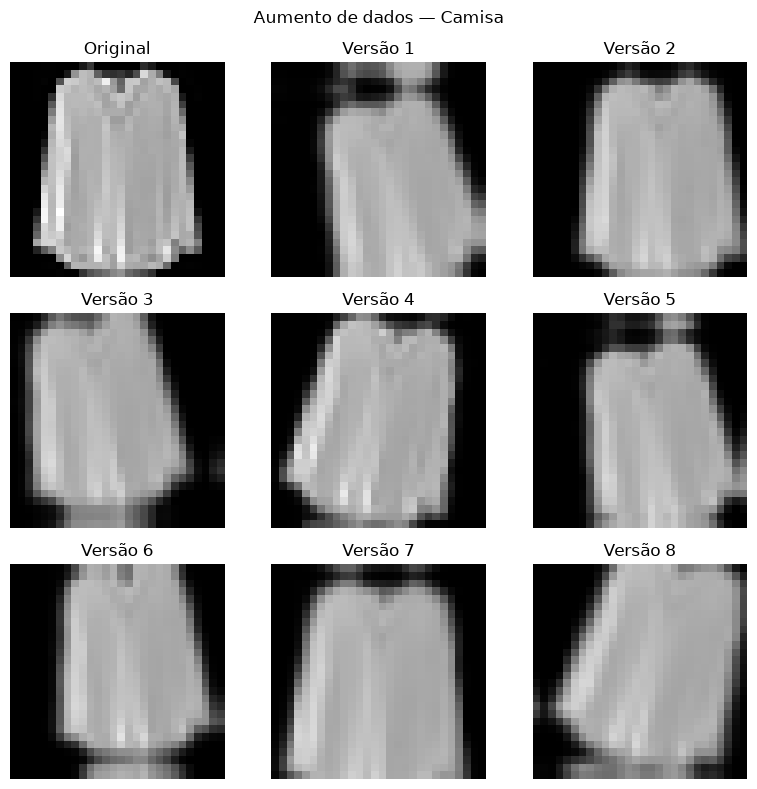

Conferido: aumento de dados desativado em modo de avaliação.


In [8]:
# Adaptado da Aula Prática 21, data_augmentation e sua visualização.
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    keras.layers.RandomZoom(0.1),
], name='aumento_dados')

img = X_train[0]
fig, eixos = plt.subplots(3, 3, figsize=(8, 8))
eixos.flat[0].imshow(img.squeeze(), cmap='gray', vmin=0, vmax=1)
eixos.flat[0].set_title('Original')
eixos.flat[0].axis('off')
for i, eixo in enumerate(eixos.flat[1:], start=1):
    augmented = data_augmentation(tf.expand_dims(img, 0), training=True)
    eixo.imshow(augmented[0].numpy().squeeze(), cmap='gray', vmin=0, vmax=1)
    eixo.set_title(f'Versão {i}')
    eixo.axis('off')
fig.suptitle(f'Aumento de dados — {NOMES_CLASSES[int(y_train[0])]}')
fig.tight_layout()
fig.savefig(RESULTADOS / 'aumento_dados_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

# Em avaliação, o aumento de dados deve devolver as imagens sem transformação.
np.testing.assert_allclose(
    data_augmentation(X_val[:32], training=False).numpy(), X_val[:32],
)
print('Conferido: aumento de dados desativado em modo de avaliação.')

### Passo 2 — Construir e compilar a CNN

Uma convolução aplica filtros aprendidos a regiões da imagem, produzindo mapas
de características. Os pesos de cada filtro são compartilhados entre posições.
Isso permite explorar a organização espacial dos pixels, diferentemente da MLP,
que recebe diretamente o vetor de pixels em sua camada densa.

Seguimos o `model3` da aula: três `Conv2D` com **8, 16 e 32 filtros**, kernels 3 × 3
e ativação ReLU; `MaxPooling2D` de 2 × 2; `Flatten`; `Dense(64, relu)`; e saída
`Dense(10, softmax)`. ReLU calcula o máximo entre zero e a entrada. O pooling
retém o maior valor de cada janela, reduzindo as dimensões espaciais dos mapas.

As convoluções sem padding adicional reduzem os tamanhos: 28 → 26 → 24 → 22.
O pooling gera mapas de 11 × 11 × 32, e o `Flatten` produz um vetor de 3.872
valores. A rede tem **254.410 parâmetros treináveis**; as transformações e o
pooling não aprendem pesos.

Inserimos `data_augmentation` logo após a entrada, como na aula. Compilamos com
Adam e taxa explícita 0,001, perda `sparse_categorical_crossentropy` e acurácia,
mantendo a mesma perda e o mesmo otimizador da MLP. Os dez rótulos inteiros e a
saída softmax já são compatíveis com o Fashion-MNIST.

In [9]:
# Adaptado da Aula Prática 21, model3 (CNN com aumento de dados).
model_cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    data_augmentation,
    keras.layers.Conv2D(filters=8, kernel_size=(3, 3), activation='relu'),
    keras.layers.Conv2D(filters=16, kernel_size=(3, 3), activation='relu'),
    keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax'),
])

model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_dados (Sequential)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       247,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 254,410 (993.79 KB)

 Trainable params: 254,410 (993.79 KB)

 Non-trainable params: 0 (0.00 B)

### Passo 3 — Treinar e salvar o histórico

Treinamos por **20 épocas, com lotes de 32**, a mesma quantidade utilizada na MLP.
A aula utiliza 10 épocas neste exemplo; ampliamos para 20 para manter o mesmo
orçamento em épocas na comparação. Isso não torna os tempos de processamento iguais.
Não utilizamos parada antecipada nem busca de hiperparâmetros nesta etapa.

Substituímos `validation_split=0.2` da aula por `validation_data=(X_val, y_val)`:
os modelos usam exatamente as mesmas 48.000 imagens de treino e 12.000 de validação
estratificada. No treino, a CNN recebe versões aleatórias das imagens; na validação,
recebe as imagens normalizadas sem essas transformações.

As métricas de treino são acumuladas com aumento de dados e pesos em atualização.
As de validação são calculadas ao final de cada época sem aumento e sem atualização.
Portanto, uma acurácia de validação maior que a de treino não é, isoladamente,
um sinal de erro ou de vazamento de dados.

Salvamos o histórico em `resultados/historico_cnn.csv` e o modelo da última época
em `modelos/cnn.keras`. Identificar a menor perda no histórico não restaura os
pesos dessa época. O teste permanece reservado para a avaliação após a otimização.

In [10]:
history_cnn = model_cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=2,
)

historico_cnn = pd.DataFrame(history_cnn.history)
historico_cnn.index = pd.RangeIndex(1, len(historico_cnn) + 1, name='epoca')
historico_cnn.to_csv(RESULTADOS / 'historico_cnn.csv')
model_cnn.save(MODELOS / 'cnn.keras')

display(historico_cnn.iloc[[0, -1]])
print('Época de menor loss de validação:', historico_cnn['val_loss'].idxmin())

Epoch 1/20


W0000 00:00:1794089565.369237   83807 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


1500/1500 - 28s - 19ms/step - accuracy: 0.7359 - loss: 0.6964 - val_accuracy: 0.7801 - val_loss: 0.5978


Epoch 2/20


1500/1500 - 28s - 18ms/step - accuracy: 0.8031 - loss: 0.5237 - val_accuracy: 0.8216 - val_loss: 0.5099


Epoch 3/20


... (33 outputs left out)

Epoch 20/20


1500/1500 - 26s - 18ms/step - accuracy: 0.8879 - loss: 0.3022 - val_accuracy: 0.8863 - val_loss: 0.3254


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.735917,0.696397,0.780083,0.597846
20,0.887854,0.302214,0.886333,0.325389


Época de menor loss de validação: 20


### Passo 4 — Visualizar as curvas e comparar com a MLP

Adaptamos os gráficos de `history3` da aula para mostrar perda e acurácia de treino
e validação, com épocas numeradas de 1 a 20. Valores menores de perda e maiores
de acurácia são favoráveis, mas as métricas não precisam variar proporcionalmente,
conforme a explicação do item 1.

A tabela compara as métricas registradas na **última época** de cada modelo.
As métricas de validação usam as mesmas imagens sem transformações; já as de
treino da CNN incluem aumento de dados, e as da MLP não. A comparação mede duas
configurações completas: arquitetura, ativação, quantidade de parâmetros e aumento
de dados mudam juntos. Ela não isola o efeito de cada escolha nem comprova, sozinha,
o benefício do aumento de dados, pois não treinamos esta mesma CNN sem aumento.

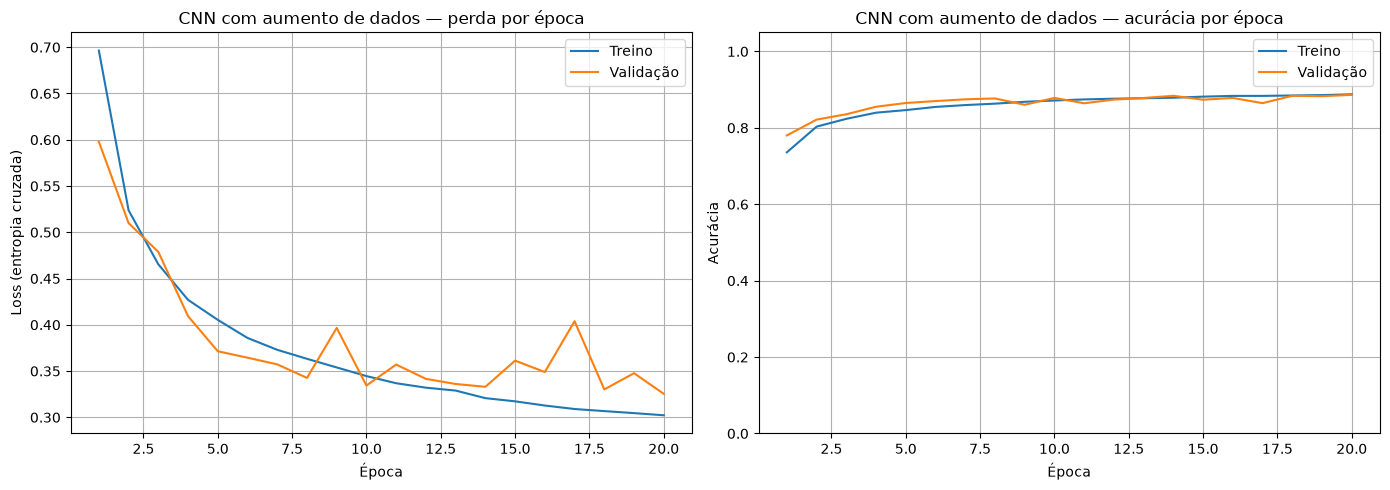

,accuracy,loss,val_accuracy,val_loss,epocas
modelo,,,,,
MLP,0.938333,0.170362,0.886000,0.360267,20
CNN com aumento de dados,0.887854,0.302214,0.886333,0.325389,20


In [11]:
# Adaptado dos gráficos de history3 da Aula Prática 21.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(historico_cnn.index, historico_cnn['loss'], label='Treino')
ax[0].plot(historico_cnn.index, historico_cnn['val_loss'], label='Validação')
ax[0].set_title('CNN com aumento de dados — perda por época')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Loss (entropia cruzada)')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(historico_cnn.index, historico_cnn['accuracy'], label='Treino')
ax[1].plot(historico_cnn.index, historico_cnn['val_accuracy'], label='Validação')
ax[1].set_title('CNN com aumento de dados — acurácia por época')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Acurácia')
ax[1].set_ylim(0, 1.05)
ax[1].grid(True)
ax[1].legend()

fig.tight_layout()
fig.savefig(RESULTADOS / 'curvas_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

comparacao_modelos = pd.DataFrame([
    historico_mlp.iloc[-1], historico_cnn.iloc[-1],
], index=['MLP', 'CNN com aumento de dados'])
comparacao_modelos.index.name = 'modelo'
comparacao_modelos['epocas'] = [len(historico_mlp), len(historico_cnn)]
display(comparacao_modelos)
comparacao_modelos.to_csv(RESULTADOS / 'comparacao_mlp_cnn.csv')

### Passo 5 — Analisar os resultados da CNN

**Finalidade do aumento de dados.** As rotações, translações e variações de escala
apresentam novas versões das imagens durante o treino, buscando reduzir a
dependência de posições e orientações específicas. O painel foi inspecionado:
a camisa continua reconhecível, mas algumas versões se aproximam das bordas.
Transformações pequenas também podem alterar detalhes; essa técnica precisa ser
avaliada junto com o desempenho, sem garantir melhoria por si só. A verificação
em modo de avaliação confirmou a ausência de transformação no lote conferido.

**Resultados medidos.** A CNN foi treinada por 20 épocas. A tabela mostra a
primeira e a última; nesta execução, a época 20 também apresentou a menor perda
e a maior acurácia de validação.

| Momento | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | --- | --- | --- | --- |
| Época 1 | 0,6964 | 73,59% | 0,5978 | 78,01% |
| Época 20 | 0,3022 | 88,79% | 0,3254 | 88,63% |

**O desempenho é satisfatório?** Como configuração inicial, sim: a validação
atingiu 88,63% de acertos, bem acima dos 10% de um classificador que sempre
escolhesse uma única classe nessa divisão balanceada. Essa referência de 10%
decorre da distribuição dos rótulos, não do treinamento de outro modelo.
O enunciado não exige uma acurácia mínima, e o resultado não demonstra que a
configuração seja ótima.

**Sobreajuste ou subajuste.** A loss de treino caiu de 0,6964 para 0,3022, e a
de validação de 0,5978 para 0,3254. Houve oscilações: na época 17, a loss de
validação subiu para 0,4039, mas depois voltou a cair, atingindo o mínimo na
época 20. Não observamos a tendência persistente de piora da loss de validação
que apareceu na MLP após a época 6. Isso não prova ausência de sobreajuste.
Também não há um padrão claro de subajuste severo: o modelo melhora no treino
e na validação ao longo da execução.

A diferença final entre as acurácias é de aproximadamente 0,15 ponto percentual.
Esse valor precisa ser interpretado com cuidado: o treino da CNN recebe imagens
transformadas e acumula métricas durante as atualizações; a validação recebe
imagens sem aumento e é medida ao final da época. A diferença menor que a da
MLP não isola nem comprova o efeito do aumento de dados.

**Perda e acurácia.** A acurácia considera a classe de maior probabilidade,
enquanto a perda considera a probabilidade da classe verdadeira, conforme as
fórmulas do item 1. Na validação da CNN, entre as épocas 9 e 17, a acurácia
passou de 86,04% para 86,46%, enquanto a perda aumentou de 0,3966 para 0,4039.
Esse exemplo real mostra que uma pequena melhora na proporção de acertos pode
coexistir com piora na perda, sem proporcionalidade entre as métricas.

**Comparação com a MLP na última época:**

| Modelo | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | --- | --- | --- | --- |
| MLP | 0,1704 | 93,83% | 0,3603 | 88,60% |
| CNN com aumento de dados | 0,3022 | 88,79% | 0,3254 | 88,63% |

A acurácia de validação da CNN foi apenas cerca de **0,03 ponto percentual**
maior, equivalente a **quatro acertos adicionais nas 12.000 imagens**. Essa
diferença pequena, obtida em uma única execução, não sustenta uma conclusão de
superioridade consistente. A loss final de validação foi menor na CNN, indicando
melhor resultado nesse critério para as configurações e épocas comparadas.

A MLP teve acurácia de treino maior, mas o treino da CNN inclui transformações
que podem dificultar os exemplos. Arquitetura, ativação, quantidade de parâmetros
e aumento de dados mudam juntos. Não treinamos esta mesma CNN sem aumento;
portanto, não podemos atribuir isoladamente a ele as diferenças observadas.

**Custo do treinamento.** Nos logs desta execução em CPU, as épocas da CNN
levaram aproximadamente 24 a 28 segundos, enquanto as da MLP levaram 3 a 4
segundos. São tempos arredondados do Keras, sujeitos à carga e ao ambiente, e
não um benchmark. A CNN também tem mais parâmetros: 254.410, contra 101.770
da MLP, além das operações espaciais e das transformações.

**Generalização e limites.** A validação indica aprendizado útil para imagens
que não atualizaram os pesos, com desempenho de acurácia próximo ao da MLP.
O resultado se limita a esta divisão e execução. A semente não garante reprodução
exata entre ambientes. O arquivo `modelos/cnn.keras` contém os pesos da época 20,
que neste histórico coincidiu com os melhores resultados de validação.
O conjunto de teste permanece reservado; a otimização e a avaliação final ainda
serão realizadas nos itens 3 e 4.

## 5.1. Experimentação e otimização da CNN (item 3)

### Passo 1 — Escolher os valores e o orçamento da busca

**Base prática:** função `build_model(hp)`, `kt.RandomSearch`, tabela de tentativas
e recuperação do melhor modelo da [Aula 23 — Treinamento de modelos](Aulas_Praticas/Aula_23_Treinamento_de_modelos_ESTUDANTE.ipynb),
de autoria da Profa. Nathalia da Cruz Alves. A [documentação do item 3](doc/ITEM_3_HIPERPARAMETROS.md)
explica o código e como realizar novos testes.

Hiperparâmetros são escolhas feitas antes do treinamento; pesos e vieses são
parâmetros aprendidos. O Random Search sorteia combinações dentro das opções
informadas, treina cada uma e compara seus resultados de validação.

**Para a equipe testar:** edite apenas `HIPERPARAMETROS` e as variáveis de orçamento
na próxima célula. Ao mudar qualquer configuração, escolha um novo `NOME_BUSCA`,
por exemplo `fashion_mnist_busca_02`. Execute os passos 1 a 5 desta seção em ordem,
com os dados já preparados. Repetir o mesmo nome com a mesma configuração permite
reabrir uma busca; uma configuração diferente com nome antigo será recusada.
Após reiniciar o kernel, execute primeiro as seções 1 a 3 para recriar os dados.
Para testar uma única combinação, use listas com um valor e `MAX_TENTATIVAS = 1`.

Espaço inicial, com 32 combinações possíveis:

- Primeira convolução: 8 ou 16 filtros.
- Segunda convolução: 16 ou 32 filtros.
- Camada densa: 32 ou 64 neurônios.
- Dropout: 0,0 ou 0,3, comparando ausência dessa regularização e descarte de 30%.
- Taxa de aprendizagem do Adam: 0,001 ou 0,0001.

Variar os filtros e os neurônios altera a capacidade e o custo da rede. Dropout
desativa aleatoriamente parte das ativações no treino, podendo reduzir dependência
de unidades específicas, mas também dificultar o aprendizado. A taxa de aprendizagem
controla a escala das atualizações; uma taxa menor pode exigir mais épocas.

São **cinco tentativas de cinco épocas**, com uma execução por tentativa e lotes
de 32, seguindo o orçamento curto da aula. Não testamos todas as combinações.
O critério é a **maior `val_accuracy`**; o teste não participa da seleção.
Os históricos e checkpoints do tuner ficam em pastas separadas pelo nome da busca.

In [5]:
import keras_tuner as kt

# EDITE AQUI: as listas contêm os valores que o Random Search pode sortear.
HIPERPARAMETROS = {
    'filters_1': [8, 16],
    'filters_2': [16, 32],
    'dense_units': [32, 64],
    'dropout_rate': [0.0, 0.3],
    'learning_rate': [0.001, 0.0001],
}
MAX_TENTATIVAS = 5
EPOCAS_POR_TENTATIVA = 5
BATCH_SIZE_BUSCA = 32
NOME_BUSCA = 'fashion_mnist_busca_01'  # Use outro nome para uma nova configuração.

PASTA_BUSCAS = RESULTADOS / 'buscas_cnn'
PASTA_BUSCA = PASTA_BUSCAS / NOME_BUSCA
configuracao_busca = {
    'hiperparametros': HIPERPARAMETROS,
    'max_tentativas': MAX_TENTATIVAS,
    'epocas_por_tentativa': EPOCAS_POR_TENTATIVA,
    'batch_size': BATCH_SIZE_BUSCA,
    'seed': SEED,
    'objetivo': 'val_accuracy',
    'arquitetura': 'CNN do item 2 com Dropout após Dense',
}
arquivo_configuracao = PASTA_BUSCA / 'configuracao_busca.json'
if arquivo_configuracao.exists():
    assert json.loads(arquivo_configuracao.read_text()) == configuracao_busca, (
        'Configuração diferente da busca salva. Escolha um novo NOME_BUSCA.'
    )
PASTA_BUSCA.mkdir(parents=True, exist_ok=True)
arquivo_configuracao.write_text(
    json.dumps(configuracao_busca, indent=2, ensure_ascii=False), encoding='utf-8',
)

print('Keras Tuner:', kt.__version__)
display(pd.DataFrame([
    {'hiperparametro': nome, 'valores': valores}
    for nome, valores in HIPERPARAMETROS.items()
]))
print(f'Busca: {NOME_BUSCA} | até {MAX_TENTATIVAS} tentativas')
print(f'Épocas por tentativa: {EPOCAS_POR_TENTATIVA} | lote: {BATCH_SIZE_BUSCA}')

Keras Tuner: 1.4.8


,hiperparametro,valores
0,filters_1,"[8, 16]"
1,filters_2,"[16, 32]"
2,dense_units,"[32, 64]"
3,dropout_rate,"[0.0, 0.3]"
4,learning_rate,"[0.001, 0.0001]"


Busca: fashion_mnist_busca_01 | até 5 tentativas
Épocas por tentativa: 5 | lote: 32


### Passo 2 — Construir uma CNN para cada combinação

Como na aula 23, `build_model(hp)` constrói e compila um modelo. Cada `hp.Choice`
busca uma opção na lista correspondente do bloco anterior. Criamos novas camadas
e um novo bloco de aumento em cada construção, sem reutilizar pesos treinados.

Adaptamos a função para manter a sequência da CNN do item 2: três convoluções
3 × 3 com ReLU, pooling 2 × 2, `Flatten`, camada densa e saída softmax. A terceira
convolução continua com 32 filtros; os fatores de aumento são 0,05, 0,1 e 0,1.
Assim, não introduzimos a mudança de topologia e BatchNormalization do exemplo
da aula 23. A novidade testada é o Dropout após a camada densa, como na função
da aula; taxa zero equivale a não descartar ativações.

O dropout e o aumento atuam apenas no treino. Validação e teste usam o modelo
em modo de avaliação. A quantidade de camadas, o tamanho dos kernels, a ativação
e os fatores de aumento ficam fixos nesta busca, para limitar o espaço experimental.

In [6]:
# Adaptado de build_model(hp) da Aula Prática 23 e da CNN do item 2.
def build_model(hp):
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.Sequential([
            keras.layers.RandomRotation(0.05),
            keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
            keras.layers.RandomZoom(0.1),
        ], name='aumento_dados'),
        keras.layers.Conv2D(
            filters=hp.Choice('filters_1', HIPERPARAMETROS['filters_1']),
            kernel_size=(3, 3), activation='relu',
        ),
        keras.layers.Conv2D(
            filters=hp.Choice('filters_2', HIPERPARAMETROS['filters_2']),
            kernel_size=(3, 3), activation='relu',
        ),
        keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(
            units=hp.Choice('dense_units', HIPERPARAMETROS['dense_units']),
            activation='relu',
        ),
        keras.layers.Dropout(
            rate=hp.Choice('dropout_rate', HIPERPARAMETROS['dropout_rate']),
        ),
        keras.layers.Dense(10, activation='softmax'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=hp.Choice('learning_rate', HIPERPARAMETROS['learning_rate']),
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

### Passo 3 — Executar o Random Search

`kt.RandomSearch` recebe a função de construção, o objetivo e o número máximo
de tentativas. A semente controla o sorteio das combinações; também configuramos
a semente geral antes da busca, sem prometer reprodução exata entre ambientes
ou após retomadas.

`overwrite=False` preserva os experimentos nomeados. Se a configuração e o nome
forem os mesmos, o tuner pode reutilizar tentativas já concluídas e retomar a busca.
A conferência do passo 1 evita reutilizar esse nome com outras opções ou orçamento.

`tuner.search` utiliza as mesmas 48.000 imagens de treino e 12.000 de validação.
Não há parada antecipada: cada tentativa concluída executa as cinco épocas
configuradas. O tuner salva o checkpoint da época de maior acurácia de validação
de cada tentativa, que pode ser anterior à última. Essa é a regra de seleção.

In [7]:
keras.utils.set_random_seed(SEED)
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=MAX_TENTATIVAS,
    executions_per_trial=1,
    seed=SEED,
    directory=str(PASTA_BUSCAS),
    project_name=NOME_BUSCA,
    overwrite=False,
)

tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS_POR_TENTATIVA,
    batch_size=BATCH_SIZE_BUSCA,
    verbose=2,
)

Trial 5 Complete [00h 02m 41s]
val_accuracy: 0.8600833415985107

Best val_accuracy So Far: 0.8600833415985107
Total elapsed time: 00h 12m 51s


### Passo 4 — Organizar os experimentos em uma tabela

Percorremos `tuner.oracle.trials`, como na aula, para registrar as combinações
e os resultados reais. A tabela inclui status, filtros, neurônios, dropout,
taxa de aprendizagem, lote, épocas configuradas e melhor época de cada tentativa.

**As quatro métricas pertencem à época selecionada por `val_accuracy`**, registrada
pelo Keras Tuner; não misturamos a maior acurácia de uma época com a menor perda
de outra. `trial.best_step` começa em zero, por isso somamos 1 para mostrar a época.
As épocas informadas para tentativas concluídas correspondem ao orçamento completo,
pois não usamos parada antecipada. Para falhas, o total executado não é inferido.

Ordenamos por acurácia de validação decrescente e exportamos a tabela para
`resultados/experimentos_cnn.csv` e para a pasta desta busca. O arquivo na raiz
de resultados representa a última busca exportada; as pastas nomeadas preservam
os resultados anteriores.

In [8]:
# Adaptado da tabela de trials da Aula Prática 23.
resultados_busca = []
for trial in tuner.oracle.trials.values():
    linha = {
        'tentativa': trial.trial_id,
        'status': trial.status,
        **trial.hyperparameters.values,
        'camadas_conv': 3,
        'filters_3': 32,
        'batch_size': BATCH_SIZE_BUSCA,
        'epocas_executadas': EPOCAS_POR_TENTATIVA if trial.status == 'COMPLETED' else None,
    }
    if trial.score is not None:
        linha['melhor_epoca'] = int(trial.best_step) + 1
        for metrica in ('loss', 'accuracy', 'val_loss', 'val_accuracy'):
            linha[metrica] = trial.metrics.get_best_value(metrica)
    resultados_busca.append(linha)

experimentos_cnn = pd.DataFrame(resultados_busca).sort_values(
    'val_accuracy', ascending=False, na_position='last',
).reset_index(drop=True)
experimentos_cnn.insert(0, 'posicao', range(1, len(experimentos_cnn) + 1))
display(experimentos_cnn)
experimentos_cnn.to_csv(RESULTADOS / 'experimentos_cnn.csv', index=False)
experimentos_cnn.to_csv(PASTA_BUSCA / 'experimentos_cnn.csv', index=False)

,posicao,tentativa,status,filters_1,filters_2,dense_units,dropout_rate,learning_rate,camadas_conv,filters_3,batch_size,epocas_executadas,melhor_epoca,loss,accuracy,val_loss,val_accuracy
0,1,4,COMPLETED,8,32,64,0.3,0.0010,3,32,32,5,5,0.483535,0.819438,0.406147,0.860083
1,2,1,COMPLETED,8,32,32,0.0,0.0010,3,32,32,5,4,0.446553,0.833313,0.413113,0.850667
2,3,3,COMPLETED,16,16,32,0.0,0.0010,3,32,32,5,4,0.453133,0.830500,0.433673,0.849250
3,4,2,COMPLETED,16,32,64,0.0,0.0001,3,32,32,5,5,0.571409,0.787646,0.552341,0.793667
4,5,0,COMPLETED,16,16,32,0.0,0.0001,3,32,32,5,5,0.604011,0.774854,0.564051,0.785750


### Passo 5 — Recuperar e salvar o melhor modelo

`get_best_models(1)` recupera os pesos do checkpoint selecionado pela validação,
como na aula. `get_best_hyperparameters(1)` recupera a combinação correspondente.
Não reconstruímos e treinamos um modelo novo para atribuir a ele as métricas da
busca, nem utilizamos o teste para escolher o vencedor.

Salvamos `melhor_modelo` em `modelos/melhor_cnn.keras` e a combinação, a tentativa,
a época e a configuração da busca em `modelos/melhor_cnn_configuracao.json`.
Esses arquivos representam a busca exportada mais recentemente. Os checkpoints
de outras buscas continuam disponíveis nas pastas do tuner.

O item 4 poderá utilizar `melhor_modelo` desta sessão ou carregar esse arquivo
para a avaliação final. O melhor modelo aqui significa o melhor entre as
combinações e épocas efetivamente testadas, não uma garantia de ótimo global.

In [9]:
melhor_trial = tuner.oracle.get_best_trials(num_trials=1)[0]
melhores_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
melhor_modelo = tuner.get_best_models(num_models=1)[0]

melhor_configuracao = {
    'nome_busca': NOME_BUSCA,
    'tentativa': melhor_trial.trial_id,
    'melhor_epoca': int(melhor_trial.best_step) + 1,
    'hiperparametros': melhores_hp.values,
    'val_accuracy': float(melhor_trial.score),
    'val_loss': float(melhor_trial.metrics.get_best_value('val_loss')),
    'configuracao_busca': configuracao_busca,
}
melhor_modelo.save(MODELOS / 'melhor_cnn.keras')
(MODELOS / 'melhor_cnn_configuracao.json').write_text(
    json.dumps(melhor_configuracao, indent=2, ensure_ascii=False), encoding='utf-8',
)
print(json.dumps(melhor_configuracao, indent=2, ensure_ascii=False))
melhor_modelo.summary()

{
  "nome_busca": "fashion_mnist_busca_01",
  "tentativa": "4",
  "melhor_epoca": 5,
  "hiperparametros": {
    "filters_1": 8,
    "filters_2": 32,
    "dense_units": 64,
    "dropout_rate": 0.3,
    "learning_rate": 0.001
  },
  "val_accuracy": 0.8600833415985107,
  "val_loss": 0.4061472713947296,
  "configuracao_busca": {
    "hiperparametros": {
      "filters_1": [
        8,
        16
      ],
      "filters_2": [
        16,
        32
      ],
      "dense_units": [
        32,
        64
      ],
      "dropout_rate": [
        0.0,
        0.3
      ],
      "learning_rate": [
        0.001,
        0.0001
      ]
    },
    "max_tentativas": 5,
    "epocas_por_tentativa": 5,
    "batch_size": 32,
    "seed": 42,
    "objetivo": "val_accuracy",
    "arquitetura": "CNN do item 2 com Dropout após Dense"
  }
}


/opt/conda/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_dados (Sequential)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       247,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 260,186 (1016.35 KB)

 Trainable params: 260,186 (1016.35 KB)

 Non-trainable params: 0 (0.00 B)

### Passo 6 — Analisar os hiperparâmetros

**Experimentos realizados.** A busca `fashion_mnist_busca_01` concluiu cinco
tentativas, cada uma com cinco épocas e lotes de 32, sem utilizar o teste.
O espaço continha 32 combinações possíveis. A tabela resumida abaixo está
ordenada por acurácia de validação; a tabela completa, nas saídas e no CSV,
também registra status, campos fixos e métricas de treino da época selecionada.
Os identificadores começam em zero: a tentativa `0` foi a primeira executada.

| Tentativa | Filtros 1 | Filtros 2 | Neurônios | Dropout | Learning rate | Melhor época | Acurácia val. | Loss val. |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 4 | 8 | 32 | 64 | 0,3 | 0,0010 | 5 | 86,01% | 0,4061 |
| 1 | 8 | 32 | 32 | 0,0 | 0,0010 | 4 | 85,07% | 0,4131 |
| 3 | 16 | 16 | 32 | 0,0 | 0,0010 | 4 | 84,93% | 0,4337 |
| 2 | 16 | 32 | 64 | 0,0 | 0,0001 | 5 | 79,37% | 0,5523 |
| 0 | 16 | 16 | 32 | 0,0 | 0,0001 | 5 | 78,57% | 0,5641 |

**Melhores valores encontrados.** A tentativa `4` foi escolhida
pela maior acurácia de validação, na época **5**:

- Primeira convolução: **8 filtros**.
- Segunda convolução: **32 filtros**.
- Terceira convolução: **32 filtros**, fixos em todas as tentativas.
- Camada densa: **64 neurônios**.
- Dropout: **0,3**.
- Taxa de aprendizagem: **0,0010**.
- Acurácia de validação: **86,01%**.
- Loss de validação: **0,4061**.

O arquivo `modelos/melhor_cnn.keras` foi recarregado e conferido nas mesmas imagens
de validação, reproduzindo as métricas do checkpoint selecionado. O modelo tem
260.186 parâmetros treináveis. O teste não participou dessa conferência.

**Taxa de aprendizagem: diferença mais marcante observada.** As tentativas `0`
e `3` usaram os mesmos filtros, 16 e 16, os mesmos 32 neurônios densos e dropout
zero. Mudou a taxa do Adam: 0,0001 e 0,001, respectivamente. A acurácia de
validação passou de 78,57% para
84,93%, uma diferença de aproximadamente
**6,35 pontos percentuais**,
calculada antes do arredondamento da tabela.

Esse resultado é compatível com aprendizado mais rápido ao utilizar 0,001 neste
orçamento curto: atualizações menores podem exigir mais épocas para atingir um
resultado semelhante. Ainda assim, foi uma execução por configuração, com
variabilidade de inicialização e treinamento; não demonstramos que essa taxa
será superior em todos os orçamentos ou arquiteturas.

**Combinações de filtros.** As tentativas `1` e `3` utilizaram a mesma taxa 0,001,
32 neurônios e dropout zero, mas filtros 8/32 e 16/16. Obtiveram, respectivamente,
85,07% e 84,93%
de validação, diferença de apenas
0,14 ponto percentual.
As duas camadas mudaram juntas; essa comparação não determina o efeito isolado
dos filtros de cada camada. Os resultados próximos também não sustentam a ideia
de que simplesmente aumentar filtros em uma camada garante maior acurácia.

**Neurônios e dropout.** A tentativa `4` manteve os filtros 8/32 e a taxa 0,001
da tentativa `1`, mas aumentou a camada densa de 32 para 64 neurônios e passou
o dropout de zero para 0,3. A acurácia subiu de
85,07% para 86,01%,
aproximadamente 0,94
ponto percentual. Uma camada maior pode aumentar a capacidade de representação,
e o dropout pode reduzir dependências entre ativações; porém, ambos mudaram
juntos. Não podemos atribuir a melhoria apenas ao dropout ou apenas aos neurônios.

Com taxa 0,0001, as tentativas `0` e `2` também mudaram simultaneamente filtros
da segunda convolução e neurônios densos. Seus resultados foram próximos,
78,57% e 79,37%.
Nesta amostra, a diferença associada ao par de taxas foi maior que essas
diferenças entre combinações de capacidade; isso descreve os cinco testes,
sem estabelecer uma ordenação universal de importância dos hiperparâmetros.

**Métricas da mesma época.** A tentativa `1` foi selecionada na época 4, com
acurácia de validação de 85,07% e loss
0,4131. Na época 5, a loss caiu para aproximadamente
0,4123, mas a acurácia caiu para 84,86%. Como o objetivo é a acurácia, a tabela
registra a época 4 e sua loss correspondente. Não combinamos métricas de épocas
diferentes para apresentar um resultado artificialmente melhor.

**Comparação com o item 2 e limites.** A CNN anterior atingiu 88,63% de validação
após 20 épocas, enquanto a melhor desta busca atingiu
86,01% em cinco épocas. A busca curta não demonstrou
melhoria em relação àquela execução. Os orçamentos são diferentes e não permitem
atribuir a diferença apenas aos hiperparâmetros. A configuração vencedora ainda
melhorou na última época, o que também limita conclusões sobre convergência.

As métricas de treino da melhor tentativa foram 81,94%
de acurácia e loss 0,4835, com aumento de dados e dropout ativos.
A validação usa imagens sem essas transformações e sem descarte de ativações;
portanto, sua acurácia maior que a de treino não é, isoladamente, sinal de erro.

O resultado representa o melhor entre as combinações realmente testadas, com
uma execução por combinação e uma única divisão. Para novos testes, a equipe
pode editar as listas ou o orçamento e escolher outro `NOME_BUSCA`, preservando
este experimento. Se ampliar as épocas para comparar com o item 2, os novos
resultados deverão ser executados e analisados, sem reutilizar as conclusões atuais.
A avaliação independente no conjunto de teste permanece para o item 4.

## 6. Avaliação final no teste (item 4)

**Executar apenas após finalizar a seleção da CNN.** Carregar as 10.000 imagens de
teste com `carregar_idx('t10k')`, normalizar com a mesma transformação e adicionar
o canal. Utilizar o melhor modelo selecionado na seção anterior.

Apresentar loss e acurácia finais, previsões e matriz de confusão com os nomes das
dez classes. Discutir as confusões mais frequentes e a capacidade de generalização.
O resultado de teste não deve orientar novas escolhas de hiperparâmetros.

In [ ]:
# TODO: carregar e preparar o teste, usando a mesma escala e formato do treino.
# TODO: avaliar a melhor CNN e apresentar loss e acurácia finais.
# TODO: gerar previsões e matriz de confusão com as dez classes identificadas.

### Discussão final — preencher após executar

Comparar teste e validação, comentar as classes mais confundidas e discutir as
limitações dos experimentos. Retomar a comparação entre MLP e CNN com as métricas
medidas, sem presumir que uma arquitetura necessariamente foi superior.

**Resposta da equipe:** preencher.

## 7. Checklist de entrega

- [ ] Nomes dos participantes e contribuição de cada um preenchidos.
- [ ] Explicações conceituais antes das implementações.
- [x] MLP treinada com curvas e análise.
- [x] CNN treinada com curvas e análise.
- [x] Tabela de hiperparâmetros, melhores valores e justificativa.
- [ ] Avaliação final com loss, acurácia e matriz de confusão.
- [ ] Notebook executado em ordem, com as saídas reais salvas.
- [ ] Referências e finalidades do uso de IA atualizadas.
- [ ] Vídeo de até 8 minutos e links de entrega conferidos.

## 8. Referências e registro de apoio

- Profa. Nathalia da Cruz Alves: enunciado, slides em `Conteudo/` e notebooks em
  `Aulas_Praticas/`. Manter a autoria quando adaptar materiais das aulas.
- Han Xiao, Kashif Rasul e Roland Vollgraf (2017).
  [Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms](https://arxiv.org/abs/1708.07747).
- [Repositório oficial do Fashion-MNIST: dados, classes e checksums](https://github.com/zalandoresearch/fashion-mnist).
- **OpenAI Codex:** apoio à organização inicial, documentação, download e criação
  desta base de notebook; adaptação da MLP da aula ao Fashion-MNIST, execução
  dos treinamentos, gráficos e apoio à análise dos itens 1, 2 e 3; adaptação
  da CNN e do aumento de dados da aula 21, do Random Search da aula 23,
  da tabela e recuperação do modelo; redação da documentação em `doc/`.
  A avaliação final no teste ainda não foi executada.
  A equipe deve revisar este material e atualizar o registro conforme seu uso real.
  O enunciado recomenda IA apenas para apoio à pesquisa e estabelece critérios de
  autoria e limites de uso que devem ser observados pela equipe.